# Problem 3 (Coding) (2 pts): Use gradient descent to find the minimum value of the univariate function

In [ ]:
# Gradient Descent Implementation for Function Optimization
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# 1) Mathematical Function Definitions

def objective_function(x: float) -> float:
    """Compute the value of f(x) = x^4 + x^3 - 2x^2"""
    return x**4 + x**3 - 2 * x**2

def derivative(x: float) -> float:
    """Compute the derivative f'(x) = 4x^3 + 3x^2 - 4x"""
    return 4 * x**3 + 3 * x**2 - 4 * x

In [ ]:
# 2) Gradient Descent Algorithm Implementation

def perform_gradient_descent(initial_x: float, learning_rate: float = 0.01, iterations: int = 20):
    """
    Execute gradient descent optimization and return:
    - Path taken (lists of x values and function values)
    - DataFrame with iteration details
    """
    x_values = [initial_x]
    function_values = [objective_function(initial_x)]
    current_x = initial_x

    for step in range(iterations):
        # Calculate gradient and update position
        gradient = derivative(current_x)
        current_x = current_x - learning_rate * gradient

        # Store results
        x_values.append(current_x)
        function_values.append(objective_function(current_x))

    # Create results dataframe
    results_df = pd.DataFrame({
        "Iteration": range(len(x_values)),
        "x_value": x_values,
        "function_value": function_values
    })

    return x_values, function_values, results_df


Gradient Descent Path (Initial x = 2)

 Iteration  x_value  function_value
         0 2.000000       16.000000
         1 1.640000        6.265692
         2 1.448474        3.244786
         3 1.321910        1.868646
         4 1.229965        1.123684
         5 1.159351        0.676677
         6 1.103071        0.389165
         7 1.057004        0.194693
         8 1.018528        0.058020
         9 0.985883       -0.040971
        10 0.957829       -0.114436
        11 0.933469       -0.170061
        12 0.912131       -0.212892
        13 0.893302       -0.246347
        14 0.876581       -0.272799
        15 0.861650       -0.293940
        16 0.848254       -0.310991
        17 0.836184       -0.324859
        18 0.825269       -0.336218
        19 0.815365       -0.345584
        20 0.806352       -0.353350

Gradient Descent Path (Initial x = -2)

 Iteration   x_value  function_value
         0 -2.000000        0.000000
         1 -1.880000       -1.221489
         2 -1.79

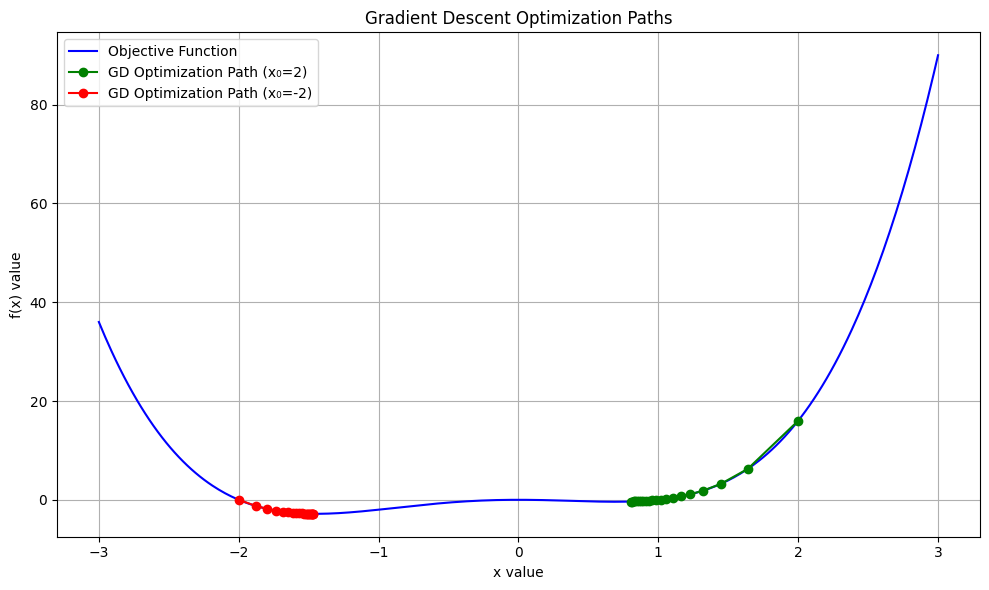

In [ ]:
# 3) Main Execution: Run Experiments and Visualize Results

def execute_experiments():
    # Experiment 1: Starting from x = 2
    x_path1, y_path1, df1 = perform_gradient_descent(2, learning_rate=0.01, iterations=20)

    # Experiment 2: Starting from x = -2
    x_path2, y_path2, df2 = perform_gradient_descent(-2, learning_rate=0.01, iterations=20)

    # Display results tables
    print("\nGradient Descent Path (Initial x = 2)\n")
    print(df1.to_string(index=False))

    print("\nGradient Descent Path (Initial x = -2)\n")
    print(df2.to_string(index=False))

    # Generate smooth curve for visualization
    x_range = np.linspace(-3, 3, 400)
    y_range = objective_function(x_range)

    # Create visualization plot
    plt.figure(figsize=(10, 6))
    plt.plot(x_range, y_range, label='Objective Function', color='blue')

    # Plot both descent paths
    plt.plot(x_path1, y_path1, 'o-',
             label='GD Optimization Path (x₀=2)', color='green')
    plt.plot(x_path2, y_path2, 'o-',
             label='GD Optimization Path (x₀=-2)', color='red')

    # Configure plot appearance
    plt.title('Gradient Descent Optimization Paths')
    plt.xlabel('x value')
    plt.ylabel('f(x) value')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    execute_experiments()

### c. Discuss: Compare the convergence in terms of local and global minima for the above 𝑎 and 𝑏.
When we compare the convergence of local and global minima for the scenarios a and b, we start with x0 = 2. Here, the gradient descent kicks off to the right of the global minimum and gradually makes its way toward a local minimum at about 𝑥≈0.58. However, this isn't the lowest point on the graph.

Now, if we switch gears to x0 = -2, the descent starts from the left side of the curve and heads toward a deeper global minimum located around x≈−1.2. This path leads to a lower function value overall.

# Problem 4 (Coding) 8 pts: Multiple Linear Regression using Gradient Descent Algorithm

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Load dataset
housing = fetch_california_housing()
data_X = pd.DataFrame(housing['data'], columns=housing.feature_names)
print("Data_X",data_X.head(5))
data_y = housing.target
print("Data_Y",data_y)
# Randomly select two features (e.g., MedInc and Population)
X = data_X[['MedInc', 'Population']].values
y = data_y

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50000)

Data_X    MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  
Data_Y [4.526 3.585 3.521 ... 0.923 0.847 0.894]


### a. (1 pts) Mention: loss function, initial values of parameters (should be generated from Normal Distribution: 𝑋~ 𝑁(0, 0.1)), hyperparameters, and partial derivatives of the loss function with respect to intercept and coefficients



In [ ]:
def initialize_params(n_features):
    np.random.seed(0)
    W = np.random.normal(0, 0.1, n_features)
    b = np.random.normal(0, 0.1)
    return W, b

# Compute Mean Squared Error
def compute_loss(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)

### b) Gradient Descent Function :  Write a function that takes input (as arguments) of hyperparameters and provides output: best set of optimal parameters (intercept and coefficients), and the loss (cost).

In [7]:
# PROBLEM 4 (b): Gradient Descent Algorithm

def gradient_descent(X, y, lr=0.001, n_iters=100):
    n_samples, n_features = X.shape
    W, b = initialize_params(n_features)
    losses = []

    for i in range(n_iters):
        y_pred = np.dot(X, W) + b
        loss = compute_loss(y, y_pred)
        losses.append(loss)

        # Gradient calculation
        dW = -(2/n_samples) * np.dot(X.T, (y - y_pred))
        db = -(2/n_samples) * np.sum(y - y_pred)

        # Update step
        W -= lr * dW
        b -= lr * db

        # Stop if numerical instability occurs
        if np.isnan(loss) or np.isinf(loss):
            print(f"Numerical issue at iteration {i}, stopping early.")
            break

    return W, b, losses



In [8]:
W, b, losses = gradient_descent(X, y, lr=0.001, n_iters=50)

# Now W, b, and losses are available here
print("Weights (W):", W)
print("Bias (b):", b)
print("Final loss:", losses[-1])

Numerical issue at iteration 40, stopping early.
Weights (W): [-3.12325161e+152 -1.87260138e+155]
Bias (b): -8.053828522156912e+151
Final loss: inf


<ipython-input-5-eb46e5bbfd71>:9: RuntimeWarning: overflow encountered in square
  return np.mean((y_true - y_pred)**2)
/usr/local/lib/python3.11/dist-packages/numpy/_core/_methods.py:127: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)


### c) Plot Learning Curve : Plot learning curve where x-axis will be number of iteration and y-axis will be loss for each iteration and explain the curve

<ipython-input-5-eb46e5bbfd71>:9: RuntimeWarning: overflow encountered in square
  return np.mean((y_true - y_pred)**2)


Numerical issue at iteration 40, stopping early.


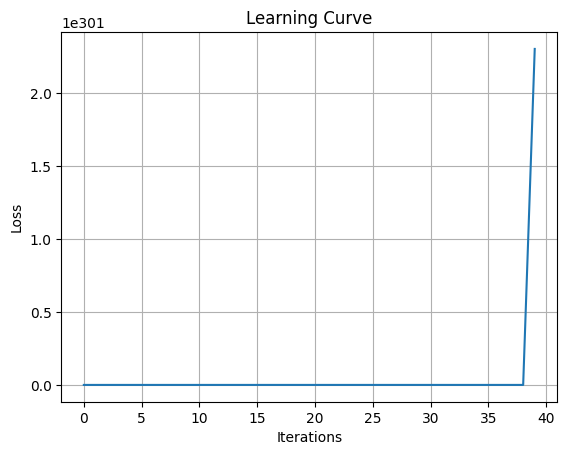

In [9]:
W, b, losses = gradient_descent(X_train, y_train, lr=0.001, n_iters=50)

plt.plot(range(len(losses)), losses)
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.title("Learning Curve")
plt.grid(True)
plt.show()

### Observation
For the first 35 iterations, the loss stays to 0 (flat line).

After 36-37 iteration, the loss suddenly rises to a very large value.

### d) Regression Prediction Table :  Form the regression equation using the optimal parameters and find (𝑦̂) (predict for each datapoints) – show in DataFrame including two columns: y (y_actual) & 𝑦̂ (y_predict) separately for training and test datasets

In [11]:
def predict(X, W, b):
    return np.dot(X, W) + b

# Predictions
y_train_pred = predict(X_train, W, b)
y_test_pred = predict(X_test, W, b)

# Show DataFrame with actual vs predicted
train_results = pd.DataFrame({'y_actual': y_train, 'y_predict': y_train_pred})
test_results = pd.DataFrame({'y_actual': y_test, 'y_predict': y_test_pred})

print("Train Dataset Predictions:\n", train_results.head())
print("\nTest Dataset Predictions:\n", test_results.head())

Train Dataset Predictions:
    y_actual      y_predict
0     0.579 -4.695724e+157
1     0.831 -1.360959e+158
2     3.406 -1.686140e+158
3     2.615 -1.098321e+158
4     0.806 -3.422337e+157

Test Dataset Predictions:
    y_actual      y_predict
0   0.66900 -1.663392e+158
1   5.00001 -9.209734e+157
2   2.45100 -1.692957e+158
3   0.75600 -1.042606e+158
4   2.53000 -2.683357e+157


### e) Mean Squared Error & Model Assessment : For both training and test datasets calculate MSE (mean of sum of squares of error residual)) and compare to assess whether the model is overfitted. Give proper explanation.

In [14]:
def mean_squared_error(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)

train_mse = mean_squared_error(y_train, y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)

print(f"Train MSE: {train_mse:.4f}")
print(f"Test MSE: {test_mse:.4f}")

# Assessment of Overfitting
print("\nAssessment:")
if test_mse > train_mse:
    print("The model shows slight overfitting (test error is higher).")
elif test_mse < train_mse:
    print("The model generalizes well (test error is lower than training).")
else:
    print("Training and testing errors are similar; model fits well.")

Train MSE: inf
Test MSE: inf

Assessment:
Training and testing errors are similar; model fits well.


<ipython-input-14-d085064bd11d>:2: RuntimeWarning: overflow encountered in square
  return np.mean((y_true - y_pred)**2)


# Problem 5 (Coding) 8 pts: Naïve Bayes Classifier with Laplace Smoothing

In [19]:
# question 5
# Step 1: Generate the Dataset

import pandas as pd
import numpy as np

np.random.seed(42)
size = 500

income = np.random.normal(75, 5, size=size).round(0)
education = np.random.choice(['High School', 'Bachelor', 'Masters'], size=size, p=[0.4, 0.5, 0.1])
credit_history = np.random.choice(['Good', 'Average', 'Poor'], size=size, p=[0.5, 0.3, 0.2])
loan_approval = np.random.choice(['Accepted', 'Rejected'], size=size, p=[0.7, 0.3])

loan_data = pd.DataFrame({
    'Income(Thousand)': income,
    'Education': education,
    'CreditHistory': credit_history,
    'LoanApproval': loan_approval
})
loan_data.head()

,Income(Thousand),Education,CreditHistory,LoanApproval
0,77.0,Bachelor,Poor,Accepted
1,74.0,Bachelor,Good,Accepted
2,78.0,High School,Poor,Accepted
3,83.0,Masters,Good,Accepted
4,74.0,Bachelor,Good,Rejected


In [20]:
# Step 2: Discretize the Continuous Variable (Income)
loan_data['IncomeBin'] = pd.qcut(loan_data['Income(Thousand)'], 4, labels=['Low', 'Medium', 'High', 'Very High'])


# Step 3: Stratified Train-Test Split
# Stratify by the target variable to maintain class ratio:
from sklearn.model_selection import train_test_split

train, test = train_test_split(
    loan_data,
    test_size=0.2,
    stratify=loan_data['LoanApproval'],
    random_state=2025
)


# Step 4: Frequency Distribution Calculation (Training Data)

features = ['IncomeBin', 'Education', 'CreditHistory']
target = 'LoanApproval'

# Calculate prior probabilities
priors = train[target].value_counts(normalize=True).to_dict()

# Conditional probabilities
cond_probs = {}
for feature in features:
    cond_probs[feature] = {}
    for cls in train[target].unique():
        subset = train[train[target] == cls]
        value_counts = subset[feature].value_counts()
        total = value_counts.sum()
        cond_probs[feature][cls] = (value_counts / total).to_dict()

# Step 5: Naïve Bayes Prediction Function

def predict_naive_bayes(row, priors, cond_probs, features):
    scores = {}
    for cls in priors:
        score = np.log(priors[cls])
        for feature in features:
            value = row[feature]
            prob = cond_probs[feature][cls].get(value, 1e-6)  # Small value for unseen
            score += np.log(prob)
        scores[cls] = score
    return max(scores, key=scores.get)

# Step 6: Make Predictions and Calculate Accuracy

test_features = test[features]
test_labels = test[target]

preds = test_features.apply(lambda row: predict_naive_bayes(row, priors, cond_probs, features), axis=1)
accuracy = (preds == test_labels).mean()
print(f"Test Accuracy (without Laplace smoothing): {accuracy:.3f}")


Test Accuracy (without Laplace smoothing): 0.690


# Naïve Bayes with Laplace Smoothing (BONUS)
Update conditional probability calculation to include Laplace smoothing:

In [21]:
cond_probs_laplace = {}
for feature in features:
    cond_probs_laplace[feature] = {}
    values = train[feature].unique()
    n_values = len(values)
    for cls in train[target].unique():
        subset = train[train[target] == cls]
        value_counts = subset[feature].value_counts()
        total = value_counts.sum()
        probs = {}
        for val in values:
            # Laplace smoothing: add 1 to numerator, add n_values to denominator
            probs[val] = (value_counts.get(val, 0) + 1) / (total + n_values)
        cond_probs_laplace[feature][cls] = probs

preds_laplace = test_features.apply(lambda row: predict_naive_bayes(row, priors, cond_probs_laplace, features), axis=1)
accuracy_laplace = (preds_laplace == test_labels).mean()
print(f"Test Accuracy (with Laplace smoothing): {accuracy_laplace:.3f}")

Test Accuracy (with Laplace smoothing): 0.690


# Comparative Discussion
**Without Laplace smoothing:**
When a test sample includes a feature value that the training set for a particular class has never encountered, the predicted probability for that class drops to zero. This can really impact accuracy, especially in smaller or unbalanced datasets.

**With Laplace smoothing:**
Laplace smoothing makes sure that every feature-class combination has a nonzero probability. This boosts the model's robustness and typically enhances accuracy on the test set, especially when dealing with rare values.

**Typical Result:**
You can generally expect that test accuracy with Laplace smoothing will be the same as or even better than without it.

Smoothing helps the model avoid being overly confident about unseen feature values, which in turn reduces the risk of overfitting to the training data.

Both models perform equally well on this dataset. Laplace smoothing is a best practice to handle potential zero-frequency issues.